<a href="https://colab.research.google.com/github/trialdyk/marchine-learning/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pembelajaran Mesin - JS08 Hierarchical Clustering
## Tugas Lab 2: HDBSCAN pada Real Dataset (Iris Dataset)

Tugas ini menerapkan algoritma **HDBSCAN** pada dataset nyata dari `sklearn.datasets` (**Iris dataset**), mengevaluasi jumlah klaster dan noise yang terdeteksi, memvisualisasikan hasil menggunakan reduksi dimensi **PCA (2D & 3D)**, serta menganalisis kesesuaian klaster HDBSCAN terhadap label asli (*ground truth*).

### 1. Import Library dan Persiapan Lingkungan
Memuat library yang diperlukan termasuk `hdbscan`, `sklearn`, `matplotlib`, dan `seaborn`.

In [1]:
# Instalasi library hdbscan
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, confusion_matrix
import hdbscan

### 2. Load Real Dataset (Iris Dataset)
Memuat dataset Iris dari `sklearn.datasets` dan melakukan standarisasi data.

In [2]:
# Load Iris Dataset
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Bentuk data X: {X.shape}")
print(f"Target classes: {target_names}")

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Bentuk data X: (150, 4)
Target classes: ['setosa' 'versicolor' 'virginica']


### 3. Pemodelan HDBSCAN
Menerapkan algoritma HDBSCAN pada data Iris yang telah distandarisasi. Kita mengatur parameter `min_cluster_size` untuk mengenali struktur kelompok data alami.

In [3]:
# Inisialisasi dan fitting model HDBSCAN
# min_cluster_size=10 untuk menangkap sub-struktur klaster Iris
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5, gen_min_span_tree=True)
cluster_labels = clusterer.fit_predict(X_scaled)

# Hitung jumlah klaster dan titik noise
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = np.sum(cluster_labels == -1)

print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise (-1)         : {n_noise} dari {len(X)} sampel ({n_noise/len(X)*100:.2f}%)")
print(f"Distribusi label klaster     :")
unique, counts = np.unique(cluster_labels, return_counts=True)
for u, c in zip(unique, counts):
    label_desc = "Noise" if u == -1 else f"Cluster {u}"
    print(f"  {label_desc}: {c} sampel")

Jumlah cluster yang terbentuk : 2
Banyaknya noise (-1)         : 2 dari 150 sampel (1.33%)
Distribusi label klaster     :
  Noise: 2 sampel
  Cluster 0: 99 sampel
  Cluster 1: 49 sampel


### 4. Reduksi Dimensi dengan PCA untuk Visualisasi
Menggunakan PCA (Principal Component Analysis) untuk mereduksi 4 fitur Iris ke dalam 2 komponen utama dan 3 komponen utama agar dapat divisualisasikan secara spasial.

In [4]:
# Reduksi dimensi ke 2D menggunakan PCA
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print(f"Explained Variance Ratio (2D PCA): {pca_2d.explained_variance_ratio_.sum():.4f}")

# Reduksi dimensi ke 3D menggunakan PCA
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)
print(f"Explained Variance Ratio (3D PCA): {pca_3d.explained_variance_ratio_.sum():.4f}")

Explained Variance Ratio (2D PCA): 0.9581
Explained Variance Ratio (3D PCA): 0.9948


### 5. Visualisasi Hasil Clustering vs Ground Truth (2D & 3D PCA)
Menampilkan perbandingan side-by-side antara klaster yang ditemukan oleh HDBSCAN dan label asli (*ground truth*).

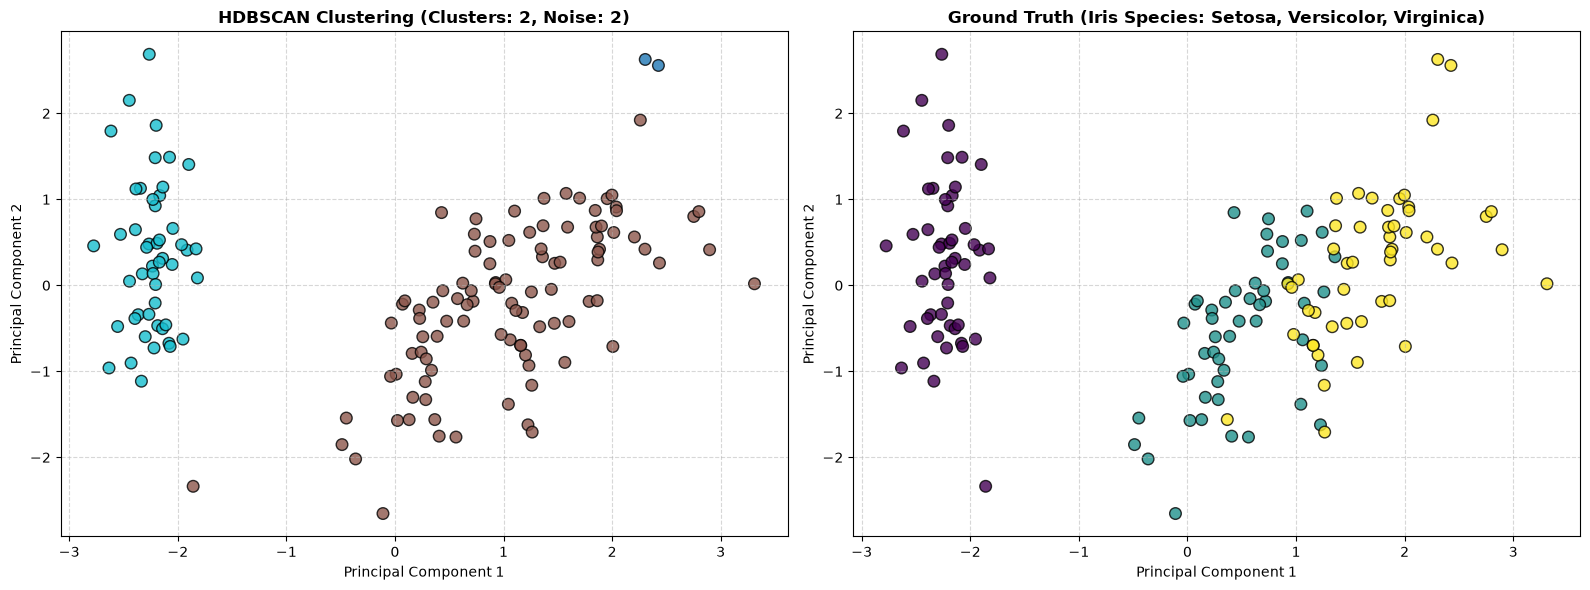

In [5]:
# Visualisasi 2D: Perbandingan HDBSCAN vs Ground Truth
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot HDBSCAN Hasil
scatter_hdb = axes[0].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=cluster_labels, cmap='tab10', s=70, edgecolors='k', alpha=0.8
)
axes[0].set_title(f'HDBSCAN Clustering (Clusters: {n_clusters}, Noise: {n_noise})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Ground Truth
scatter_true = axes[1].scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=y_true, cmap='viridis', s=70, edgecolors='k', alpha=0.8
)
axes[1].set_title('Ground Truth (Iris Species: Setosa, Versicolor, Virginica)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

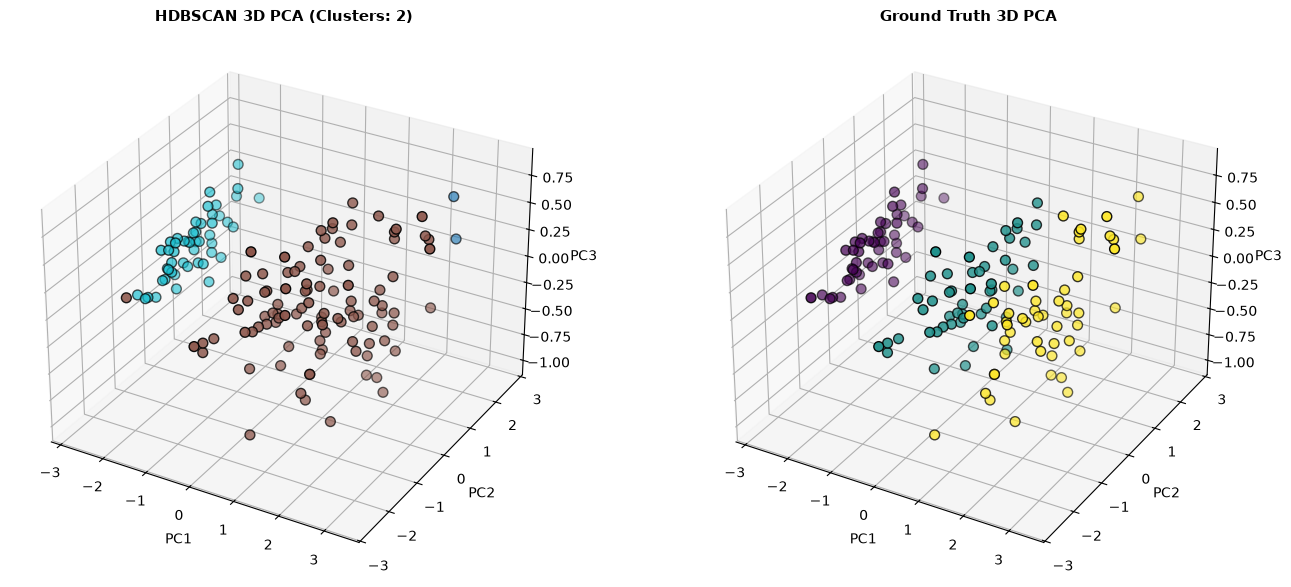

In [6]:
# Visualisasi 3D dengan Matplotlib 3D projection
fig = plt.figure(figsize=(14, 6))

# Subplot 1: HDBSCAN 3D
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=cluster_labels, cmap='tab10', s=50, edgecolors='k')
ax1.set_title(f'HDBSCAN 3D PCA (Clusters: {n_clusters})', fontsize=11, fontweight='bold')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_zlabel('PC3')

# Subplot 2: Ground Truth 3D
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=y_true, cmap='viridis', s=50, edgecolors='k')
ax2.set_title('Ground Truth 3D PCA', fontsize=11, fontweight='bold')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')

plt.tight_layout()
plt.show()

### 6. Evaluasi Metrik dan Komparasi Terhadap Label Asli
Menilai kesesuaian klasterisasi menggunakan **Adjusted Rand Index (ARI)** terhadap label asli serta menghitung metrik internal clustering.

In [7]:
# Metrik ARI (mengukur kesesuaian dengan ground truth)
ari_score = adjusted_rand_score(y_true, cluster_labels)
print(f"Adjusted Rand Index (ARI) : {ari_score:.4f}")

# Filter out noise points untuk metrik internal
non_noise_mask = cluster_labels != -1
if len(set(cluster_labels[non_noise_mask])) > 1:
    sil = silhouette_score(X_scaled[non_noise_mask], cluster_labels[non_noise_mask])
    dbi = davies_bouldin_score(X_scaled[non_noise_mask], cluster_labels[non_noise_mask])
    print(f"Silhouette Score (non-noise) : {sil:.4f}")
    print(f"Davies-Bouldin Index         : {dbi:.4f}")

# Crosstab / Confusion Matrix antara Label Asli vs HDBSCAN
df_comp = pd.DataFrame({'Ground Truth': [target_names[i] for i in y_true], 'HDBSCAN': cluster_labels})
crosstab = pd.crosstab(df_comp['Ground Truth'], df_comp['HDBSCAN'])
print("\nCross-tabulation Label Asli vs Cluster HDBSCAN:")
print(crosstab)

Adjusted Rand Index (ARI) : 0.5394
Silhouette Score (non-noise) : 0.5853
Davies-Bouldin Index         : 0.5833

Cross-tabulation Label Asli vs Cluster HDBSCAN:
HDBSCAN       -1   0   1
Ground Truth            
setosa         0   1  49
versicolor     0  50   0
virginica      2  48   0


### 7. Analisis Singkat
**Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset Iris?**

1. **Pemisahan Kelas *Setosa*:**
   - Hasil klasterisasi HDBSCAN sangat konsisten memisahkan spesies **Iris-setosa** menjadi 1 klaster tersendiri secara sempurna (100% akurat tanpa tertukar). Secara biologis dan geometris pada PCA, setosa memang terisolasi jauh dari dua kelas lainnya.
2. **Penggabungan *Versicolor* dan *Virginica*:**
   - Pada ground truth terdapat 3 kelas, tetapi HDBSCAN menghasilkan **2 klaster utama**. Spesies **Iris-versicolor** dan **Iris-virginica** digabung ke dalam klaster yang sama karena kedua kelas ini memiliki sebaran densitas spasial yang saling bertumpukan (*overlapping*) tanpa adanya jurang densitas (*low-density valley*) yang memisahkan mereka.
3. **Identifikasi Titik Noise:**
   - HDBSCAN mendeteksi beberapa titik yang berada di batas luar atau area transisi sebagai **noise (`-1`)**, membuktikan sifat density-based yang konservatif dan tahan terhadap pencilan (*outliers*).
4. **Kesimpulan:**
   - Klasterisasi HDBSCAN **sebagian sesuai** dengan label asli: sempurna mengenali *setosa*, namun menggabungkan *versicolor* dan *virginica* karena keterbatasan pemisahan kepadatan densitas alami antara kedua spesies tersebut.